# Spatial domains across platforms with Novae

This guide assembles a cohort that no single repository holds, mouse brain sections measured with MERFISH and MERSCOPE (Allen Brain Cell Atlas) and Xenium (GEO), and runs the pretrained [Novae](https://github.com/MICS-Lab/novae) model on it without further training. It shows the chain from a catalog query to a cohort, to one table with cell coordinates, to an existing method. It makes no claim about the quality of the domains.

The catalog release is a parameter, so the guide can be run again on a later release.

In [1]:
import os

os.environ.setdefault("TQDM_DISABLE", "1")  # keep progress bars out of the rendered guide
RELEASE = os.environ.get("SDDB_RELEASE", "2026-10-28")  # dated catalog release
SEED = 0

In [2]:
import anndata as ad
import lightning
import matplotlib.pyplot as plt
import novae
import numpy as np
import sddb
import torch
from spatialdata import transform
from spatialdata.transformations import get_transformation

lightning.seed_everything(SEED, workers=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("sddb", sddb.__version__ if hasattr(sddb, "__version__") else "", "| novae", novae.__version__, "| device", device)

sddb 29.dev7+g50302e533 | novae 1.1.2 | device cpu


## Query and cohort

One query selects mouse brain sections from three imaging platforms. We keep datasets with a recorded source and take the two smallest sections per platform, so that the guide runs on a laptop-sized cohort.

In [3]:
catalog = sddb.Catalog(version=RELEASE)
hits = catalog.query(organism="mouse", tissue="brain", technology=["Xenium", "Merscope", "MERFISH"])
m = hits.members.assign(source=hits.members["canonical_key"].str.split(":", n=1).str[0])
m = m[m["source"].notna()].sort_values("size_bytes").groupby("technology", group_keys=False).head(2)
cohort = catalog.cohort(uids=list(m["uid"]))
cohort.freeze().write("novae_cohort.json")  # the manifest records the members and the catalog hash
m[["uid", "technology", "source", "study_id", "n_obs", "n_features", "license"]]

,uid,technology,source,study_id,n_obs,n_features,license
57,r3rkbHVtKnv9hVKq0000,MERFISH,abc,abc:Zhuang-ABCA-1,5505,1122,allen-institute-tou
58,sLymOk4GMnZwXFXz0000,MERFISH,abc,abc:Zhuang-ABCA-1,5893,1122,allen-institute-tou
50,9cBWCjyWHTOCiVaR0000,Merscope,abc,abc:MERFISH-C57BL6J-638850,23376,550,allen-institute-tou
47,TfrvgsM9ohN1WYsz0000,Merscope,abc,abc:MERFISH-C57BL6J-638850,25780,550,allen-institute-tou
12,T9Q8m47Lh79ELPtl0000,Xenium,geo,geo:GSE318202,60038,347,ncbi-geo-policy
17,PQUO8vANoIk7YByP0000,Xenium,geo,geo:GSE318202,68239,347,ncbi-geo-policy


## One table with cell coordinates

The client reads only the count table of each member. Some tables do not store cell coordinates in `obsm["spatial"]` (the Allen MERFISH and MERSCOPE tables); for those we take the centroids of the cell shapes that the table annotates.

In [4]:
def table_with_xy(ds):
    name = ds.default_table or "table"
    t = ds.to_sdata(elements=[f"tables/{name}"]).tables[name]
    if "spatial" not in t.obsm:
        attrs = t.uns["spatialdata_attrs"]
        region = attrs["region"] if isinstance(attrs["region"], str) else attrs["region"][0]
        sd = ds.to_sdata(elements=[f"tables/{name}", f"shapes/{region}"])
        cs = sorted(get_transformation(sd.shapes[region], get_all=True), key=lambda c: c != "global")[0]
        shapes = transform(sd.shapes[region], to_coordinate_system=cs)
        cent = shapes.loc[t.obs[attrs["instance_key"]].values].geometry.centroid
        t.obsm["spatial"] = np.c_[cent.x, cent.y]
    t.obsm = {"spatial": np.asarray(t.obsm["spatial"], float)[:, :2]}
    t.obs = t.obs.assign(uid=ds.uid, technology=ds.technology)[["uid", "technology"]]
    t.var_names = t.var_names.astype(str).str.upper()
    return t[:, ~t.var_names.duplicated()].copy()


adata = ad.concat([table_with_xy(ds) for ds in cohort], join="outer", merge="first")
adata

AnnData object with n_obs × n_vars = 188831 × 1335
    obs: 'uid', 'technology'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'
    layers: 'csc_counts', None (.X)

## Novae, zero-shot

In [5]:
novae.spatial_neighbors(adata, slide_key="uid", radius=80)  # coordinates are in micrometres
model = novae.Novae.from_pretrained("MICS-Lab/novae-mouse-0")
model.compute_representations(adata, zero_shot=True, accelerator=device, num_workers=8)
key = model.assign_domains(adata, level=7)
adata.obs.groupby("technology", observed=True)[key].value_counts(normalize=True).unstack(fill_value=0).round(3)

novae_domains_7,D1006,D1011,D1012,D1014,D1016,D196,D955
technology,,,,,,,
MERFISH,0.075,0.288,0.092,0.140,0.131,0.000,0.274
Merscope,0.404,0.093,0.215,0.169,0.115,0.002,0.001
Xenium,0.428,0.133,0.207,0.047,0.164,0.000,0.020


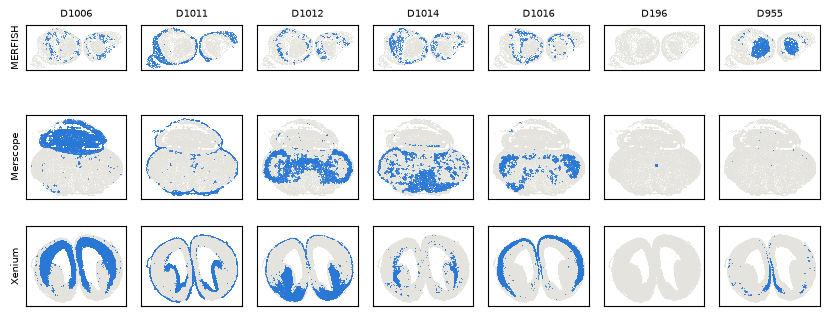

In [6]:
domains = sorted(adata.obs[key].dropna().unique())
largest = adata.obs.groupby("technology", observed=True)["uid"].agg(lambda s: s.value_counts().index[0])
fig, axes = plt.subplots(len(largest), len(domains), figsize=(1.2 * len(domains), 1.2 * len(largest)), squeeze=False)
for i, (tech, uid) in enumerate(largest.items()):
    s = adata[adata.obs["uid"] == uid]
    for j, dom in enumerate(domains):
        ax, hit = axes[i, j], (s.obs[key] == dom).to_numpy()
        ax.scatter(*s.obsm["spatial"].T, s=0.2, c="#e4e3dd", linewidths=0)
        ax.scatter(*s.obsm["spatial"][hit].T, s=0.3, c="#2a78d6", linewidths=0)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(dom, fontsize=7)
        if j == 0:
            ax.set_ylabel(tech, fontsize=7)
plt.tight_layout()